In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from scipy.stats import uniform, loguniform
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_percentage_error
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
import numpy as np

In [2]:
base = pd.read_csv('train.csv')

In [3]:
base.info()

<class 'pandas.DataFrame'>
RangeIndex: 300000 entries, 0 to 299999
Data columns (total 16 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   id      300000 non-null  int64  
 1   cont1   300000 non-null  float64
 2   cont2   300000 non-null  float64
 3   cont3   300000 non-null  float64
 4   cont4   300000 non-null  float64
 5   cont5   300000 non-null  float64
 6   cont6   300000 non-null  float64
 7   cont7   300000 non-null  float64
 8   cont8   300000 non-null  float64
 9   cont9   300000 non-null  float64
 10  cont10  300000 non-null  float64
 11  cont11  300000 non-null  float64
 12  cont12  300000 non-null  float64
 13  cont13  300000 non-null  float64
 14  cont14  300000 non-null  float64
 15  target  300000 non-null  float64
dtypes: float64(15), int64(1)
memory usage: 36.6 MB


In [4]:
base.head()

,id,cont1,cont2,cont3,cont4,cont5,cont6,cont7,cont8,cont9,cont10,cont11,cont12,cont13,cont14,target
0,1,0.670390,0.811300,0.643968,0.291791,0.284117,0.855953,0.890700,0.285542,0.558245,0.779418,0.921832,0.866772,0.878733,0.305411,7.243043
1,3,0.388053,0.621104,0.686102,0.501149,0.643790,0.449805,0.510824,0.580748,0.418335,0.432632,0.439872,0.434971,0.369957,0.369484,8.203331
2,4,0.834950,0.227436,0.301584,0.293408,0.606839,0.829175,0.506143,0.558771,0.587603,0.823312,0.567007,0.677708,0.882938,0.303047,7.776091
3,5,0.820708,0.160155,0.546887,0.726104,0.282444,0.785108,0.752758,0.823267,0.574466,0.580843,0.769594,0.818143,0.914281,0.279528,6.957716
4,8,0.935278,0.421235,0.303801,0.880214,0.665610,0.830131,0.487113,0.604157,0.874658,0.863427,0.983575,0.900464,0.935918,0.435772,7.951046


In [5]:
X = base.filter(like='cont')
y = base['target']

In [6]:
X.describe()

,cont1,cont2,cont3,cont4,cont5,cont6,cont7,cont8,cont9,cont10,cont11,cont12,cont13,cont14
count,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000,300000.000000
mean,0.506873,0.497898,0.521557,0.515683,0.502022,0.526515,0.487890,0.525163,0.459857,0.520532,0.483926,0.506877,0.553442,0.503713
std,0.203976,0.228159,0.200770,0.233035,0.220701,0.217909,0.181096,0.216221,0.196685,0.201854,0.220082,0.218947,0.229730,0.208238
min,-0.082263,-0.031397,0.020967,0.152761,0.276377,0.066166,-0.097666,0.217260,-0.240604,-0.085046,0.083277,0.088635,0.029950,0.166367
25%,0.343078,0.319170,0.344096,0.294935,0.284108,0.356163,0.346600,0.341486,0.330832,0.375465,0.300474,0.310166,0.350472,0.308673
50%,0.484005,0.553209,0.551471,0.482880,0.451733,0.470988,0.466825,0.483460,0.416843,0.458877,0.441916,0.486599,0.487707,0.431845
75%,0.643789,0.731263,0.648315,0.748705,0.670660,0.694043,0.581292,0.685250,0.575041,0.700292,0.679128,0.694453,0.768479,0.712653
max,1.016227,0.859697,1.006955,1.010402,1.034261,1.043858,1.066167,1.024427,1.004114,1.199951,1.022620,1.049025,0.977845,0.868506


In [7]:
y.describe()

count    300000.000000
mean          7.905661
std           0.733071
min           0.000000
25%           7.329367
50%           7.940571
75%           8.470084
max          10.267569
Name: target, dtype: float64

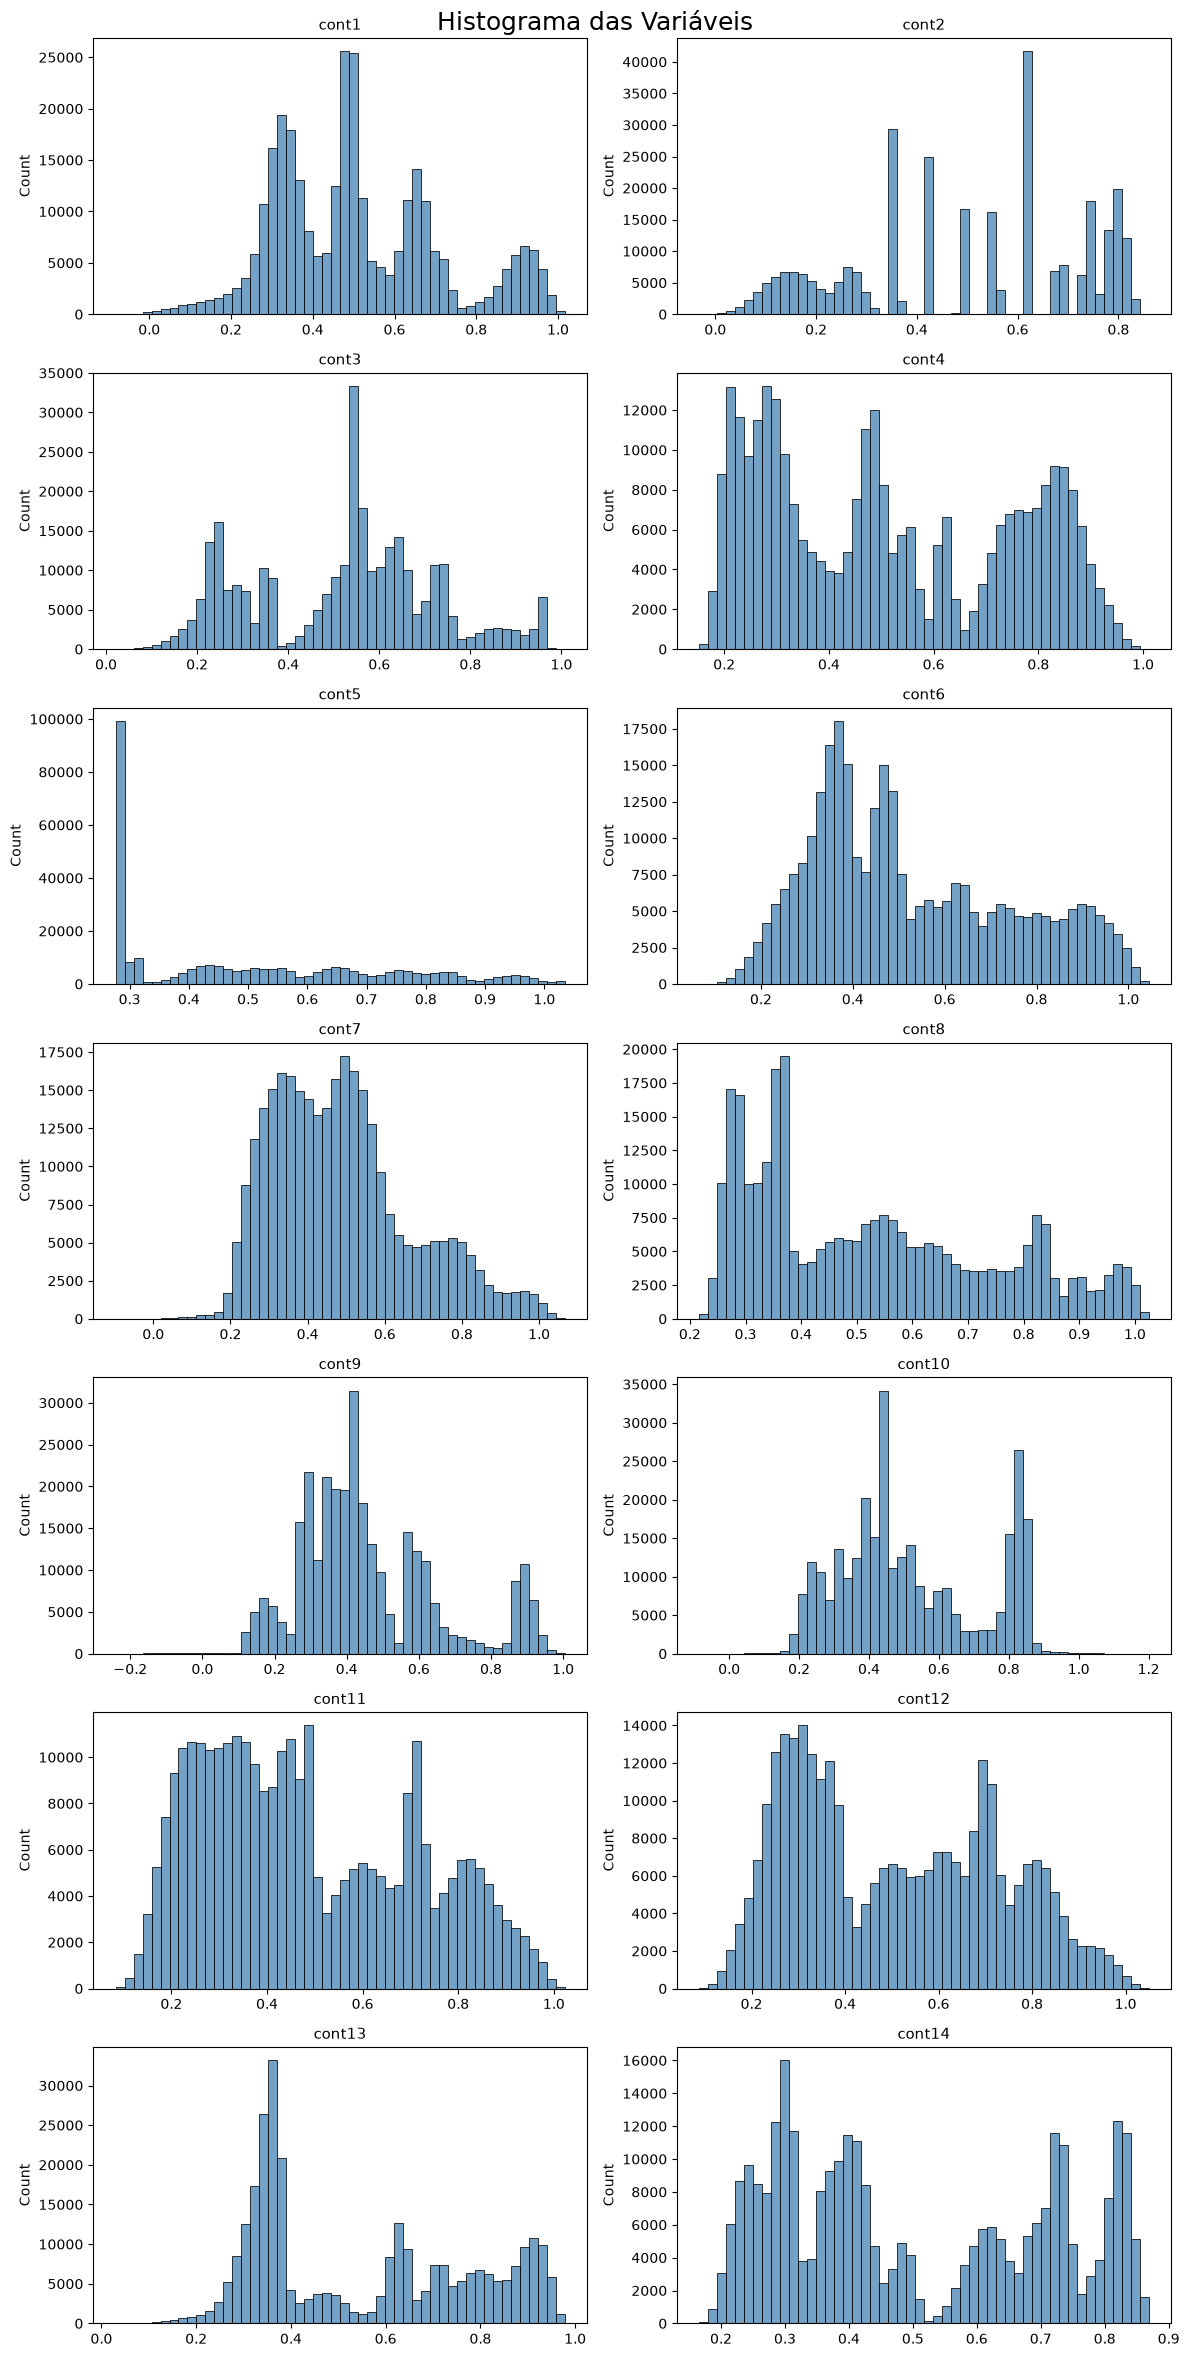

In [8]:
fig, axes = plt.subplots(nrows=7, ncols=2, figsize=(12,24))

fig.suptitle('Histograma das Variáveis', fontsize='18')

for i, ax in enumerate(axes.flatten()):
    col = X.columns[i]
    sns.histplot(X[col], bins=50, ax=ax, color='steelblue')
    ax.set_title(col, fontsize=11)
    ax.set_xlabel('')


plt.tight_layout()
plt.show()

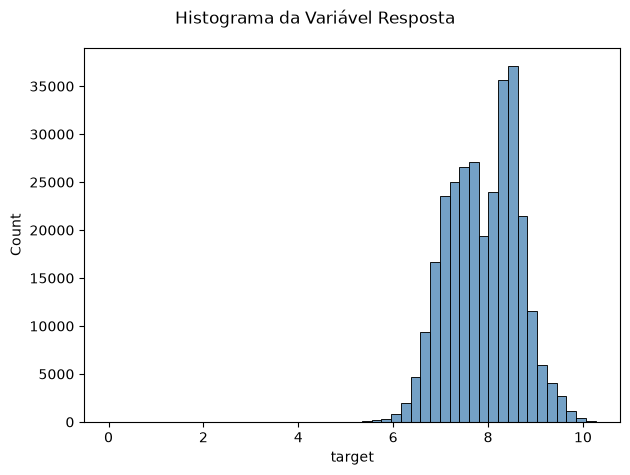

In [9]:
sns.histplot(y, bins=50, color='steelblue')
plt.suptitle('Histograma da Variável Resposta')
plt.tight_layout()
plt.show()

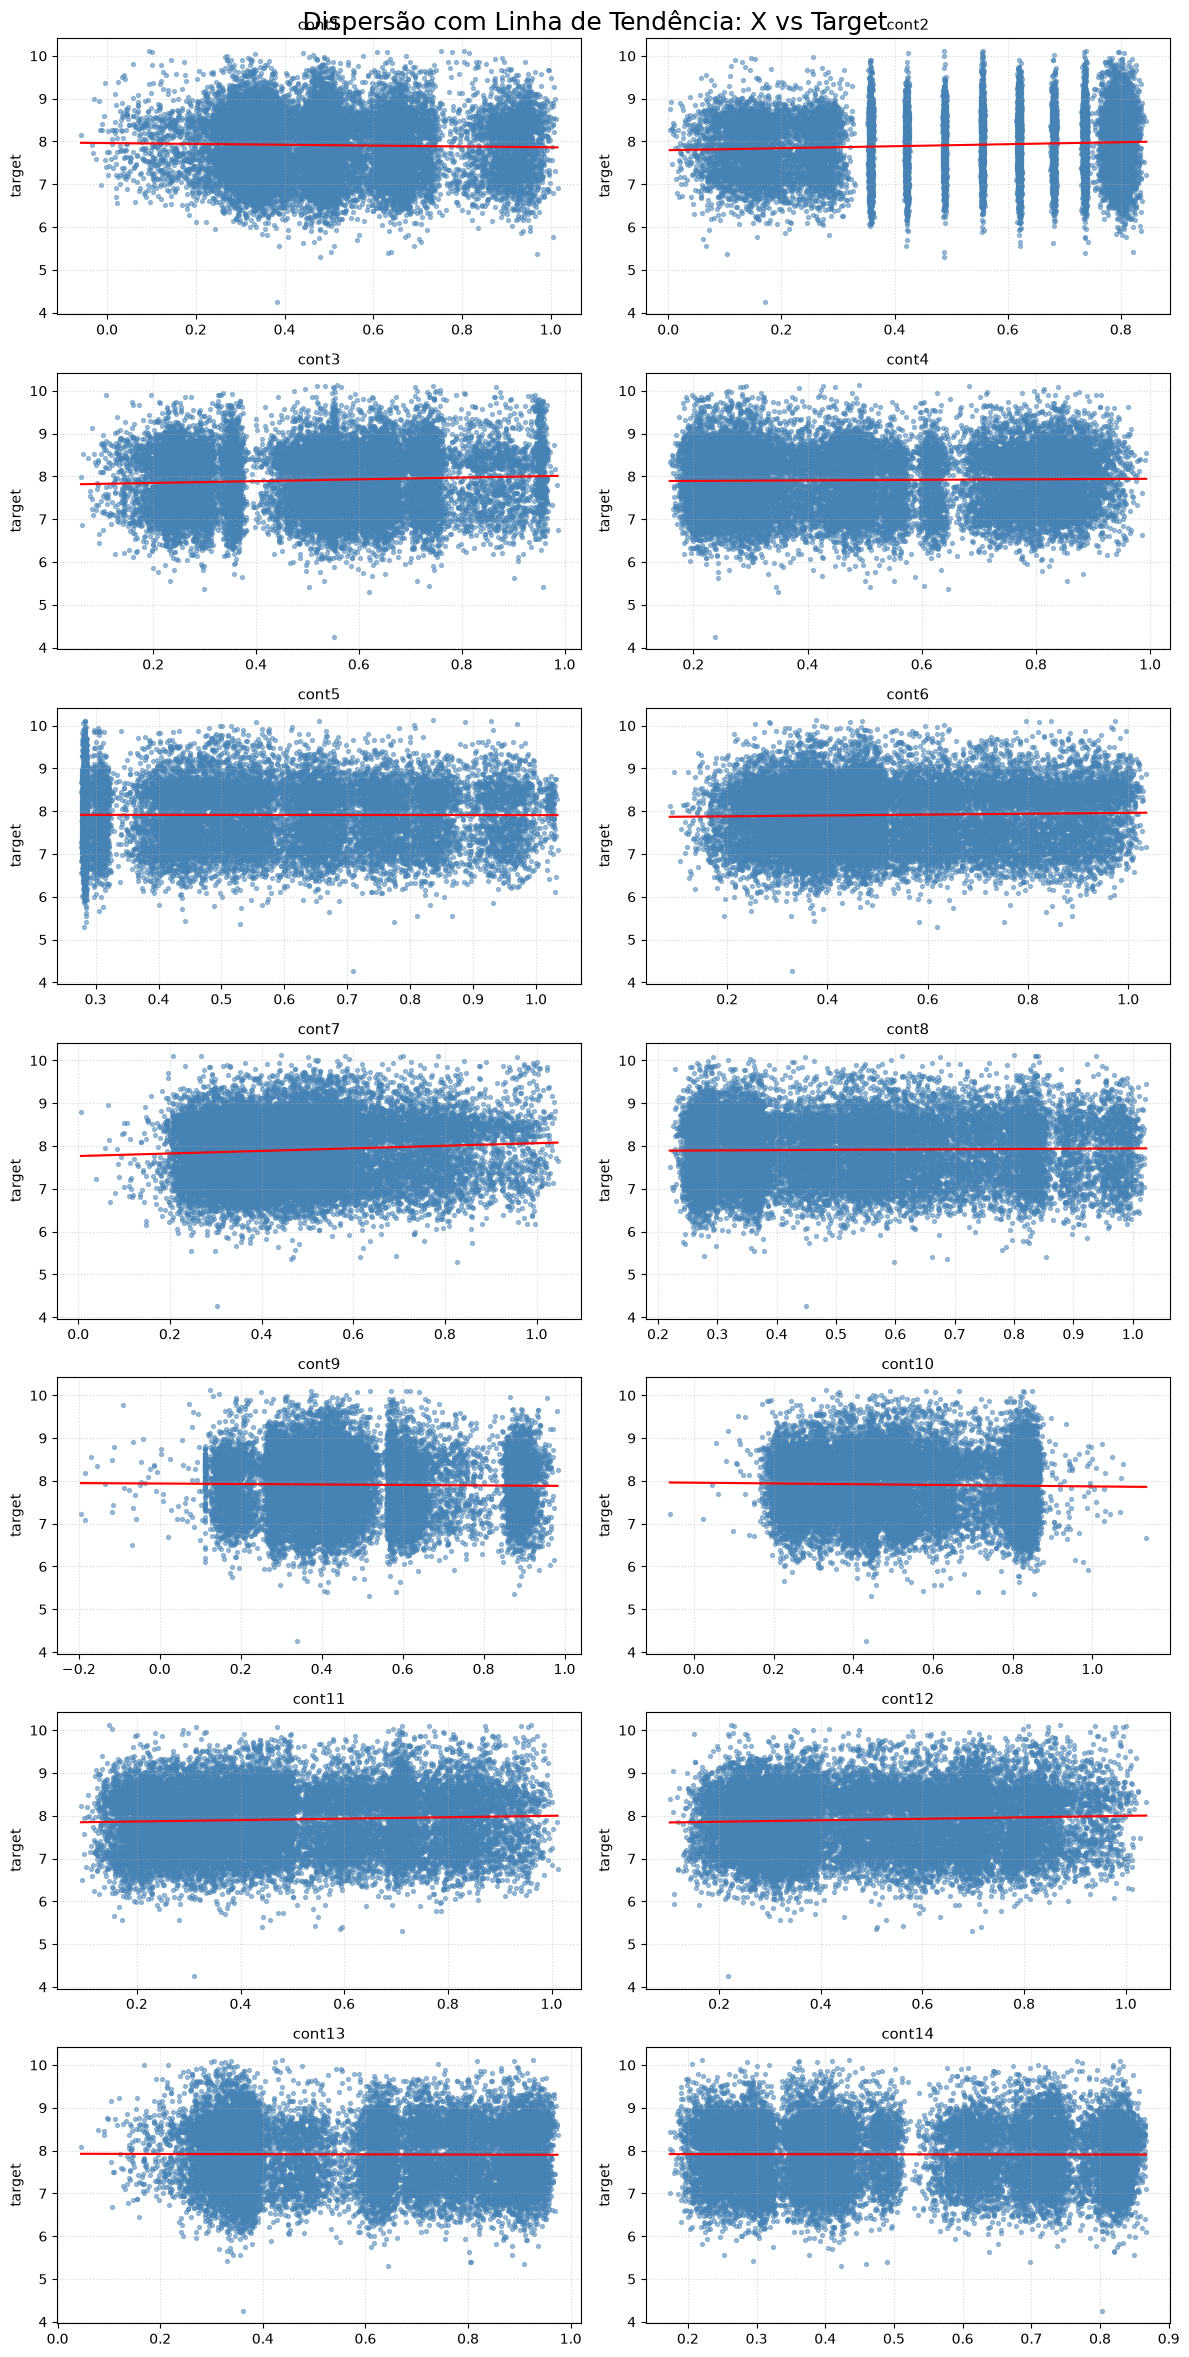

In [10]:
sample = base.sample(n=20000, random_state=42)

fig, axes = plt.subplots(nrows=7, ncols=2, figsize=(12,24))
axes = axes.flatten()

plt.suptitle('Dispersão com Linha de Tendência: X vs Target', fontsize=18)

for i, col in enumerate(X.columns):
    ax = axes[i]
    sns.regplot(
        data=sample, 
        x=col, 
        y='target', 
        ax=ax, 
        color='steelblue',
        scatter_kws={'alpha':0.5, 's':8,},
        line_kws={'color':'red', 'linewidth':1.5}
    )
    ax.set_title(col, fontsize=11)
    ax.set_xlabel('')
    ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

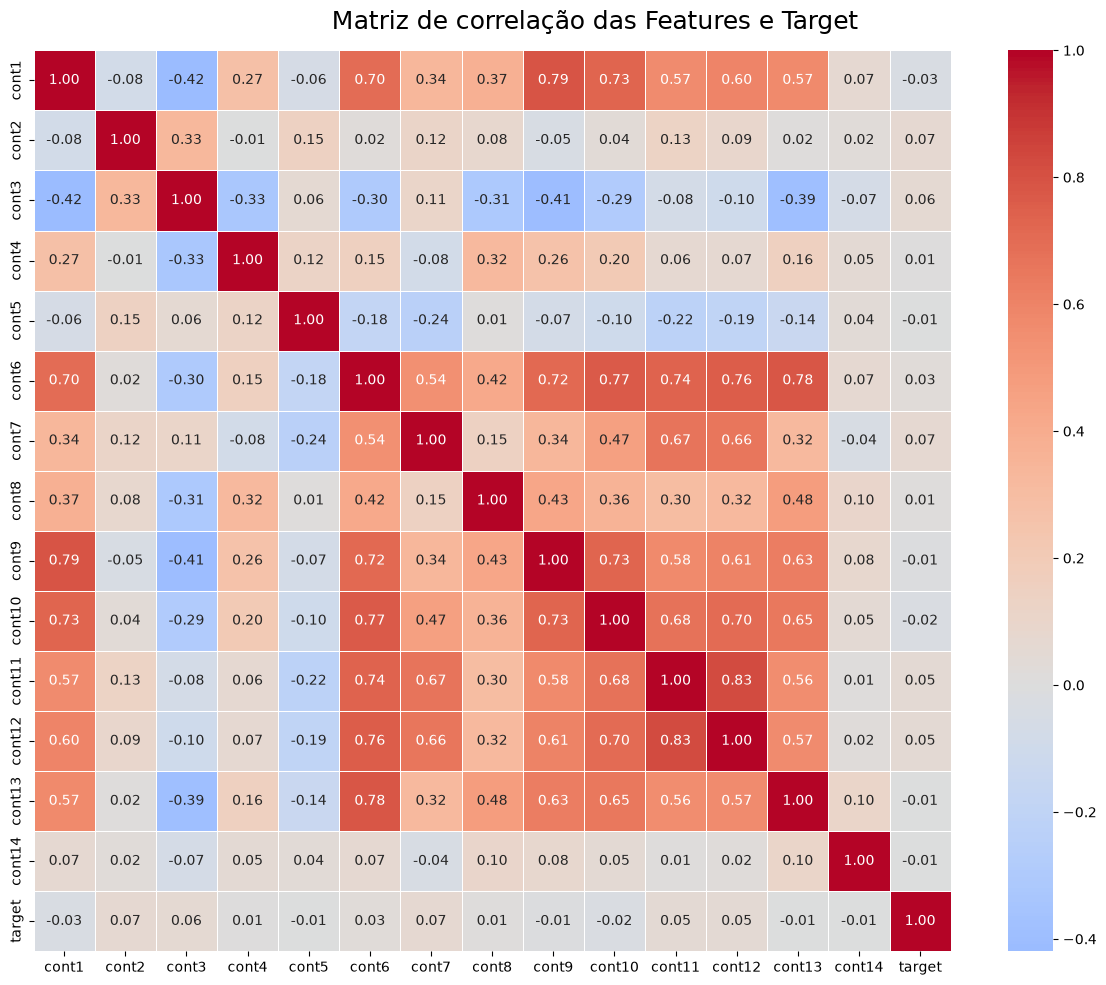

In [11]:
plt.figure(figsize=(12,10))

corr = base.drop(columns=['id']).corr()

plt.suptitle('Matriz de correlação das Features e Target', fontsize=18)

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)

plt.tight_layout()
plt.show()

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=42)

In [13]:
scaler = StandardScaler()
X_train_norm = scaler.fit_transform(X_train)
X_test_norm = scaler.transform(X_test)

In [14]:
from scipy.stats import randint
algoritmos = {
    'REGRESSÃO LINEAR': (LinearRegression(), {}),
    'RIDGE': (Ridge(), {}),
    'LASSO': (Lasso(random_state=42), {
        'alpha': loguniform(1e-5, 1e1)
    }),
    'ELASTIC NET': (ElasticNet(random_state=42), {
        'alpha': loguniform(1e-5, 1e1), 
        'l1_ratio': uniform(0, 1)
    }),
    'ARVORE DE REGRESSAO': (RandomForestRegressor(random_state=42), {
        'n_estimators': randint(10, 500),
        'min_impurity_decrease': uniform(0, 0.05),
        'min_samples_split': randint(200, 500),
        'min_samples_leaf': randint(50, 100),
        'max_samples': uniform(0.6, 0.4),
        'max_features': ['sqrt', 'log2', None],
        'max_depth': randint(2, 10)
    }),
    'GRADIENT BOOSTING COM HISTOGRAMAS': (HistGradientBoostingRegressor(random_state=42), {
        'max_iter': randint(10, 300),
        'learning_rate': loguniform(1e-4, 1e-1),
        'min_samples_leaf': randint(50, 100),
        'max_leaf_nodes': randint(10, 30),
        'max_bins': randint(10, 255),
        'l2_regularization': loguniform(1e-5, 1e2),
        'max_depth': randint(2, 10)
    }),
    'XGBOOST': (XGBRegressor(random_state=123 ), {
        'n_estimators': randint(10, 300),
        'learning_rate': loguniform(1e-4, 1e-1),
        'colsample_bytree': uniform(0.5, 0.5),
        'subsample': uniform(0.6, 0.4),
        'gamma': uniform(0, 5),
        'reg_alpha': loguniform(1e-5, 1e2),
        'reg_lambda': loguniform(1e-5, 1e2),
        'max_depth': randint(2, 10)
    }),
}

In [15]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
qtd_iter = 15

In [16]:
resultados = []
contador_modelo = 0

for nome_algoritmo, (classe_algoritmo, hiperparametros) in algoritmos.items():
    busca = RandomizedSearchCV(
        estimator=classe_algoritmo,
        param_distributions=hiperparametros,
        n_iter=1 if not hiperparametros else qtd_iter,
        scoring='neg_root_mean_squared_error',
        cv=cv,
        return_train_score=True,
        random_state=42,
        n_jobs=-1
    )

    busca.fit(X_train_norm, y_train)

    resultados_aux = pd.DataFrame({
        'num_modelo': [f'Modelo {contador_modelo + i}' for i in range(len(busca.cv_results_['params']))],
        'nome_algoritmo': nome_algoritmo,
        'classe_agoritmo': type(classe_algoritmo).__name__,
        'hiperparametros': busca.cv_results_['params'],
        'media_erro_treino': -busca.cv_results_['mean_train_score'],
        'media_erro_teste_interno': -busca.cv_results_['mean_test_score']
    })

    erro_teste = []
    for params in resultados_aux["hiperparametros"]:
        estimador = clone(classe_algoritmo).set_params(**params)
        estimador.fit(X_train_norm, y_train)
        y_hat_teste = estimador.predict(X_test_norm)
        erro = root_mean_squared_error(y_test, y_hat_teste)
        erro_teste.append(erro)
    
    resultados_aux["erro_teste_externo"] = erro_teste
    resultados_aux["var_abs_media_erro_teste_interno"] = abs(resultados_aux["media_erro_teste_interno"] - resultados_aux["media_erro_treino"])
    resultados_aux["var_abs_erro_teste_externo"] = abs(resultados_aux["erro_teste_externo"] - resultados_aux["media_erro_treino"])

    resultados.append(resultados_aux)
    contador_modelo += len(resultados_aux)

resultados = pd.concat(resultados, ignore_index=True)

In [17]:
resultados.sort_values('erro_teste_externo').head(10)

,num_modelo,nome_algoritmo,classe_agoritmo,hiperparametros,media_erro_treino,media_erro_teste_interno,erro_teste_externo,var_abs_media_erro_teste_interno,var_abs_erro_teste_externo
47,Modelo 47,GRADIENT BOOSTING COM HISTOGRAMAS,HistGradientBoostingRegressor,"{'l2_regularization': 0.004185822729546971, 'l...",0.698924,0.705434,0.702966,0.006510,0.004042
63,Modelo 63,XGBOOST,XGBRegressor,"{'colsample_bytree': 0.9330880728874675, 'gamm...",0.701513,0.708346,0.705742,0.006833,0.004229
61,Modelo 61,GRADIENT BOOSTING COM HISTOGRAMAS,HistGradientBoostingRegressor,"{'l2_regularization': 0.17446962333585553, 'le...",0.704577,0.708605,0.706449,0.004028,0.001872
69,Modelo 69,XGBOOST,XGBRegressor,"{'colsample_bytree': 0.9697494707820946, 'gamm...",0.700541,0.710732,0.708020,0.010190,0.007478
54,Modelo 54,GRADIENT BOOSTING COM HISTOGRAMAS,HistGradientBoostingRegressor,"{'l2_regularization': 0.0004866068992431117, '...",0.710813,0.713367,0.710787,0.002554,0.000026
52,Modelo 52,GRADIENT BOOSTING COM HISTOGRAMAS,HistGradientBoostingRegressor,"{'l2_regularization': 10.461232326411377, 'lea...",0.714333,0.715609,0.713137,0.001275,0.001196
64,Modelo 64,XGBOOST,XGBRegressor,"{'colsample_bytree': 0.9961057796456088, 'gamm...",0.712565,0.715969,0.713424,0.003404,0.000859
49,Modelo 49,GRADIENT BOOSTING COM HISTOGRAMAS,HistGradientBoostingRegressor,"{'l2_regularization': 2.4824531051321886e-05, ...",0.716258,0.717293,0.714866,0.001034,0.001392
57,Modelo 57,GRADIENT BOOSTING COM HISTOGRAMAS,HistGradientBoostingRegressor,"{'l2_regularization': 18.356566544355083, 'lea...",0.719967,0.720847,0.718187,0.000880,0.001780
72,Modelo 72,XGBOOST,XGBRegressor,"{'colsample_bytree': 0.9077307142274171, 'gamm...",0.721236,0.721700,0.719109,0.000464,0.002128


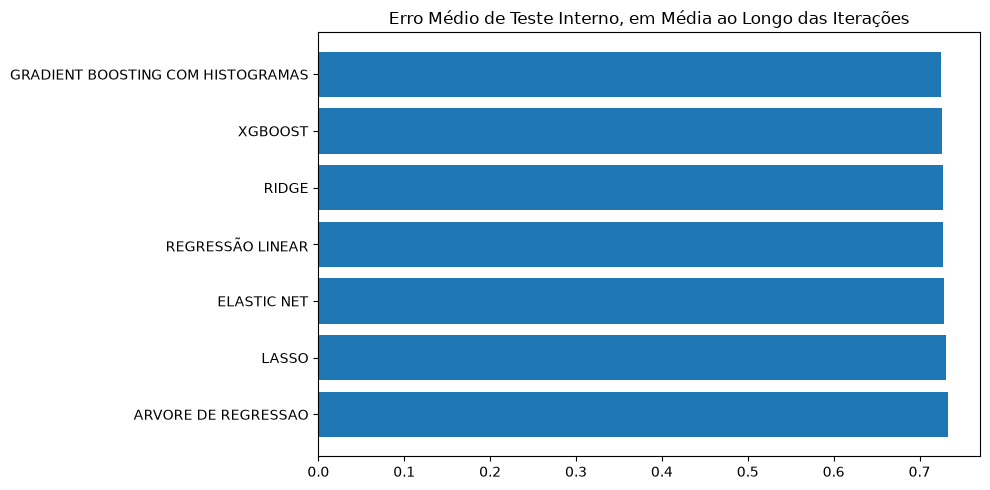

In [18]:
resumo_algoritmos = (
    resultados
    .groupby("nome_algoritmo")["media_erro_teste_interno"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
plt.barh(resumo_algoritmos.index, resumo_algoritmos.values)
plt.title("Erro Médio de Teste Interno, em Média ao Longo das Iterações")
plt.tight_layout()
plt.show()

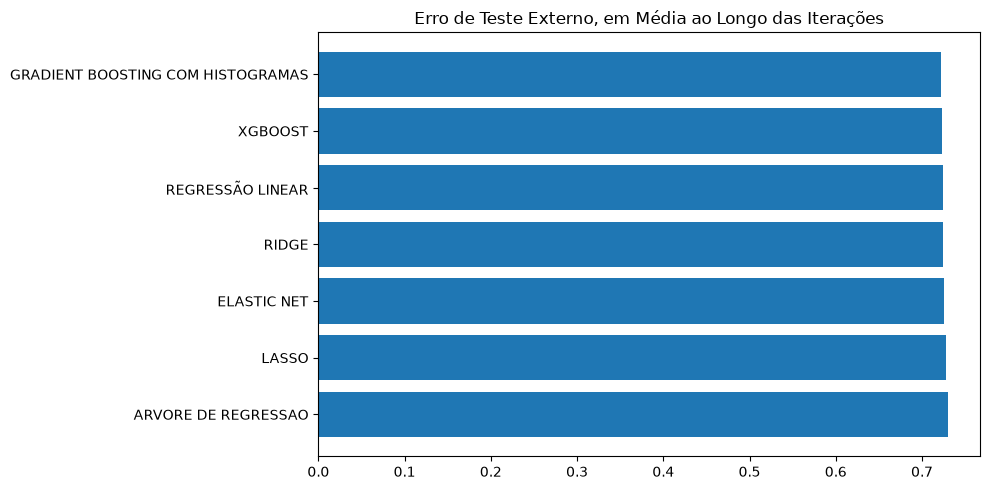

In [19]:
resumo_algoritmos = (
    resultados
    .groupby("nome_algoritmo")["erro_teste_externo"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
plt.barh(resumo_algoritmos.index, resumo_algoritmos.values)
plt.title("Erro de Teste Externo, em Média ao Longo das Iterações")
plt.tight_layout()
plt.show()

In [20]:
modelo = resultados.loc[resultados["num_modelo"] == 'Modelo 47'].squeeze()

hiperparametros_final = modelo['hiperparametros']
modelo_final = algoritmos[modelo['nome_algoritmo']][0].set_params(**hiperparametros_final)
modelo_final.fit(X_train_norm, y_train)

,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",np.float64(0....4476009343425)
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",198
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",16
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",9
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",68
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",np.float64(0....5822729546971)
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",116
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0


In [21]:
y_hat_test = modelo_final.predict(X_test_norm)

In [22]:
rmse = np.sqrt(np.mean((y_test - y_hat_test)**2))
mae = np.mean(np.abs(y_test - y_hat_test))
mape = np.mean(np.abs((y_test - y_hat_test) / y))

print(f"""
    Valor do RMSE: {rmse}, 
    Valor do MAE: {mae}, 
    Valor do MAPE: {mape}
    """)


    Valor do RMSE: 0.7029655489314972, 
    Valor do MAE: 0.590864597374598, 
    Valor do MAPE: 0.07611429234885707
    


In [23]:
r2_score(y_test, y_hat_test)
resid = y_test - y_hat_test

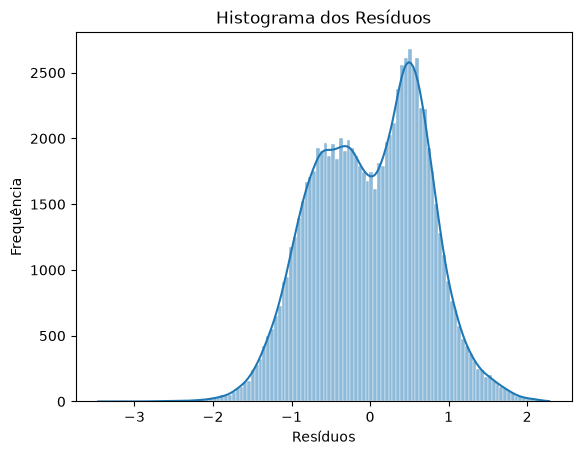

In [24]:
sns.histplot(resid,
             edgecolor="white",
             kde=True)
plt.title("Histograma dos Resíduos")
plt.xlabel("Resíduos")
plt.ylabel("Frequência")
plt.show()

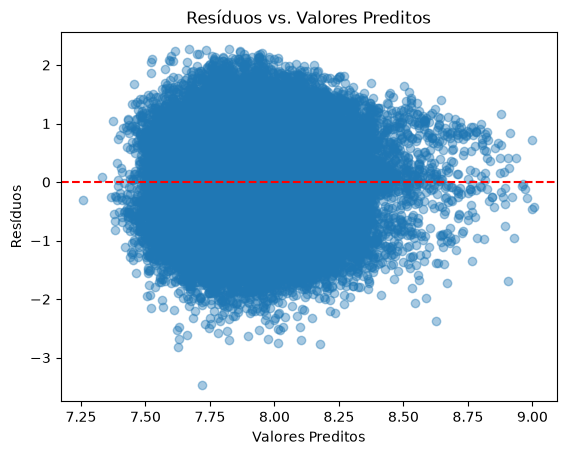

In [25]:
plt.scatter(y_hat_test,
            resid,
            alpha=0.4)
plt.axhline(0, color='red', linestyle='--')
plt.title("Resíduos vs. Valores Preditos")
plt.xlabel("Valores Preditos")
plt.ylabel("Resíduos")
plt.show()

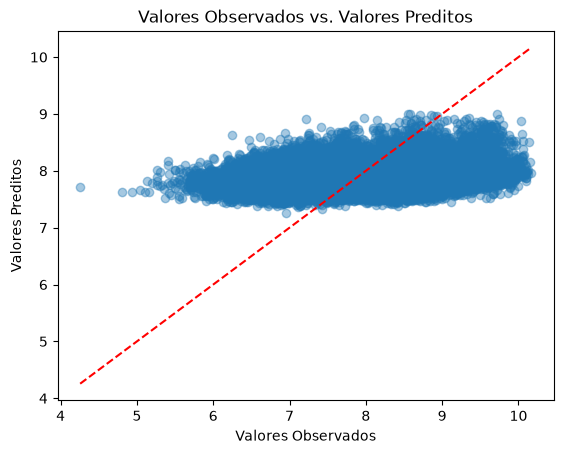

In [26]:
min_eixo = min(y_test.min(), y_hat_test.min())
max_eixo = max(y_test.max(), y_hat_test.max())
plt.scatter(y_test,
            y_hat_test,
            alpha=0.4)
plt.plot([min_eixo, max_eixo], [min_eixo, max_eixo], color='red', linestyle='--')
plt.title("Valores Observados vs. Valores Preditos")
plt.xlabel("Valores Observados")
plt.ylabel("Valores Preditos")
plt.show()

In [27]:
base_test = pd.read_csv('test.csv')
X_test_final = base_test.drop(columns='id')
X_test_final_norm = scaler.transform(X_test_final)

predict = modelo_final.predict(X_test_final_norm)

base_entrega = pd.DataFrame({
    'id': base_test['id'],
    'target': predict
})

base_entrega.to_csv('submissao.csv', index=False)